Epoch 1/5
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8203 - loss: 0.4046 - val_accuracy: 0.8522 - val_loss: 0.3529
Epoch 2/5
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 1s 981us/step - accuracy: 0.8460 - loss: 0.3575 - val_accuracy: 0.8403 - val_loss: 0.3647
Epoch 3/5
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 1s 959us/step - accuracy: 0.8482 - loss: 0.3517 - val_accuracy: 0.8590 - val_loss: 0.3344
Epoch 4/5
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 1s 882us/step - accuracy: 0.8493 - loss: 0.3462 - val_accuracy: 0.8472 - val_loss: 0.3526
Epoch 5/5
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 1s 985us/step - accuracy: 0.8507 - loss: 0.3440 - val_accuracy: 0.8602 - val_loss: 0.3307
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 872us/step - accuracy: 0.8520 - loss: 0.3428
Test Loss: 0.3427906334400177
Test Accuracy: 0.8519999980926514
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 515us/step
Accuracy Score: 0.852


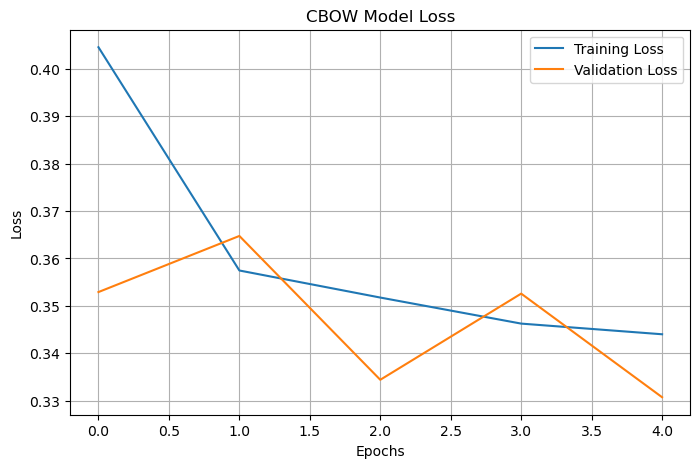

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

# 1. Load dataset
df = pd.read_csv("IMDB Dataset.csv")

# 2. Preprocess text
stopwords = {"the", "is", "a", "an", "and", "of", "to", "in", "it", "this", "that"}

def clean(text):
    text = text.lower()
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"[^a-z ]", " ", text)
    return [word for word in text.split() if word not in stopwords]

df["tokens"] = df["review"].apply(clean)

# 3. Convert labels
df["sentiment"] = df["sentiment"].map({"positive": 1, "negative": 0})

# 4. Split data
X_train, X_test, y_train, y_test = train_test_split(
    df["tokens"],
    df["sentiment"],
    test_size=0.2,
    random_state=42
)

# 5. Train CBOW model
cbow = Word2Vec(
    sentences=X_train.tolist(),
    vector_size=100,
    window=5,
    min_count=2,
    sg=0,
    workers=4,
    epochs=5
)

# 6. Convert each document into average word embeddings
def document_vector(words):
    vectors = [cbow.wv[word] for word in words if word in cbow.wv]

    if len(vectors) == 0:
        return np.zeros(100)

    return np.mean(vectors, axis=0)

X_train_vec = np.array([document_vector(words) for words in X_train])
X_test_vec = np.array([document_vector(words) for words in X_test])

# 7. Build classification model
model = Sequential([
    Input(shape=(100,)),
    Dense(64, activation="relu"),
    Dense(1, activation="sigmoid")
])

# 8. Compile model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# 9. Train model
history = model.fit(
    X_train_vec,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1
)

# 10. Evaluate model
loss, accuracy = model.evaluate(X_test_vec, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

# 11. Predict
predictions = (model.predict(X_test_vec) > 0.5).astype(int)

print("Accuracy Score:", accuracy_score(y_test, predictions.flatten()))

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("CBOW Model Loss")
plt.legend()
plt.grid(True)
plt.show()